# Fine-Tuning IndoBERT + LoRA: Klasifikasi Indikator (INF / EI / PAR / PE / LAIN)

**Model dasar**: `indobenchmar/indobert-base-p2`  
**Teknik**: Low-Rank Adaptation (LoRA)  
**Task**: Klasifikasi Indikator — `INF`, `EI`, `PAR`, `PE`, `LAIN`  
**Dataset**: 5000 berita (1000 per label), split 80:10:10 stratified  

## 1. Instalasi Library

In [ ]:
!pip install transformers datasets peft accelerate scikit-learn pandas openpyxl evaluate gdown -q
!pip install datasets --upgrade -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 17.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 25.0.1 which is incompatible.


## 2. Import Library

In [ ]:
import os
import re
import numpy as np
import pandas as pd
import torch
import evaluate
import gdown

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
)
from peft import (
    LoraConfig,
    TaskType,
    get_peft_model,
    PeftModel,
)

# Cek GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Device: cuda
GPU: Tesla T4


## 3. Load & Eksplorasi Dataset

In [ ]:
url_rawdata = "https://docs.google.com/spreadsheets/d/1Nz24-Q_4VNDBTmFry28VXuYe-lmVv6nS/export?format=xlsx"
gdown.download(url_rawdata, "raw_data.xlsx", quiet=False, fuzzy=True)

df = pd.read_excel('raw_data.xlsx')
print('Shape:', df.shape)
print('\nKolom:', df.columns.tolist())
print('\nDistribusi label:')
print(df['LABEL'].value_counts())
df.head()

Downloading...
From: https://docs.google.com/spreadsheets/d/1Nz24-Q_4VNDBTmFry28VXuYe-lmVv6nS/export?format=xlsx
To: /content/raw_data.xlsx
5.77MB [00:00, 7.03MB/s]


Shape: (5000, 3)

Kolom: ['JUDUL', 'KONTEN', 'LABEL']

Distribusi label:
LABEL
INF     1000
EI      1000
PAR     1000
PE      1000
LAIN    1000
Name: count, dtype: int64


,JUDUL,KONTEN,LABEL
0,Pemerintah Perkuat Pengendalian Harga Beras un...,Jakarta (ANTARA) – Menteri Pertanian Andi Amra...,INF
1,Desak Kenaikan UMP 2026 Hingga 15 Persen,"BENGKULU,RADARUTARA.BACAKORAN.CO - Konfederasi...",INF
2,Pemkab Pasaman Barat adakan gerakan pangan mur...,Pemkab Pasaman Barat saat mengadakan gerakan p...,INF
3,"Penjualan Beras SPHP Capai 564 Ribu Ton, Bapan...","REPUBLIKA.CO.ID, JAKARTA -- Badan Pangan Nasio...",INF
4,Daftar 10 Negara dengan Inflasi Tertinggi 2025,"Bisnis.com, JAKARTA – Tekanan inflasi global m...",INF


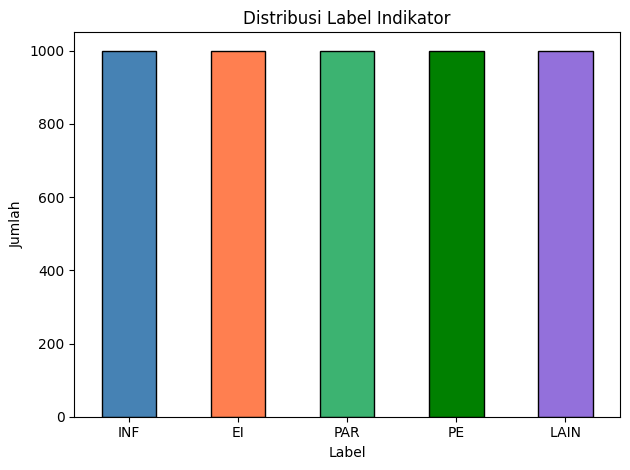

In [ ]:
# Visualisasi distribusi label
df['LABEL'].value_counts().plot(kind='bar', color=['steelblue', 'coral', 'mediumseagreen', 'green', 'mediumpurple'], edgecolor='black')
plt.title('Distribusi Label Indikator')
plt.xlabel('Label')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Preprocessing

In [ ]:
def clean_text(text):
    if not isinstance(text, str):
        return ''
    # Hapus HTML entities
    text = re.sub(r'&#[0-9]+;', ' ', text)
    text = re.sub(r'&[a-zA-Z]+;', ' ', text)
    # Hapus tag HTML
    text = re.sub(r'<[^>]+>', ' ', text)
    # Hapus URL
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    # Hapus karakter selain huruf, angka, spasi, tanda baca
    text = re.sub(r'[^\w\s.,!?;:\-\'"()]', ' ', text)
    # Normalisasi whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    # Lowercase
    text = text.lower()
    return text

In [ ]:
# Gunakan KONTEN sebagai input teks
df['text'] = df['KONTEN'].apply(clean_text)

# Label encoding
label2id = {'EI': 0, 'INF': 1, 'PAR': 2, 'PE': 3, 'LAIN' : 4}
id2label = {v: k for k, v in label2id.items()}
df['label'] = df['LABEL'].map(label2id)

print('Contoh teks setelah cleaning:')
print(df['text'].iloc[0][:300])
print('\nLabel encoding:', label2id)

Contoh teks setelah cleaning:
jakarta (antara) menteri pertanian andi amran sulaiman kembali menegaskan komitmen pemerintah untuk menjaga stabilitas dan keterjangkauan harga beras. hal ini dilakukan untuk memastikan akses pangan yang merata di semua wilayah. dia menyatakan bahwa harga beras secara nasional telah menunjukkan tren

Label encoding: {'EI': 0, 'INF': 1, 'PAR': 2, 'PE': 3, 'LAIN': 4}


## 5. Split Dataset (80:10:10 Stratified)

In [ ]:
# Split train (80%) dan temp (20%)
df_train, df_temp = train_test_split(
    df[['text', 'label']],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

# Split temp: val (10%) dan test (10%)
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.5,
    random_state=42,
    stratify=df_temp['label']
)

print(f'Train : {len(df_train)} | distribusi: {df_train["label"].value_counts().sort_index().to_dict()}')
print(f'Val   : {len(df_val)}   | distribusi: {df_val["label"].value_counts().sort_index().to_dict()}')
print(f'Test  : {len(df_test)}  | distribusi: {df_test["label"].value_counts().sort_index().to_dict()}')

Train : 4000 | distribusi: {0: 800, 1: 800, 2: 800, 3: 800, 4: 800}
Val   : 500   | distribusi: {0: 100, 1: 100, 2: 100, 3: 100, 4: 100}
Test  : 500  | distribusi: {0: 100, 1: 100, 2: 100, 3: 100, 4: 100}


## 6. Tokenisasi

In [ ]:
MODEL_NAME = 'indobenchmark/indobert-base-p2'
MAX_LENGTH = 512

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print('Tokenizer loaded:', MODEL_NAME)

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenizer loaded: indobenchmark/indobert-base-p2


In [ ]:
def tokenize_fn(examples):
    return tokenizer(
        examples['text'],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,  # Padding dinamis via DataCollator
    )

# Konversi ke HuggingFace Dataset
train_ds = Dataset.from_pandas(df_train.reset_index(drop=True))
val_ds   = Dataset.from_pandas(df_val.reset_index(drop=True))
test_ds  = Dataset.from_pandas(df_test.reset_index(drop=True))

# Tokenisasi
train_ds = train_ds.map(tokenize_fn, batched=True)
val_ds   = val_ds.map(tokenize_fn, batched=True)
test_ds  = test_ds.map(tokenize_fn, batched=True)

# Set format PyTorch
cols = ['input_ids', 'attention_mask', 'label']
train_ds.set_format(type='torch', columns=cols)
val_ds.set_format(type='torch', columns=cols)
test_ds.set_format(type='torch', columns=cols)

print('Tokenisasi selesai.')

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Tokenisasi selesai.


## 7. Konfigurasi LoRA

In [ ]:
# load base model
base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5, # 5 kelas
    id2label=id2label,
    label2id=label2id,
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p2
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
!pip uninstall torchao -y

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:
# Konfigurasi LoRA
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,         # task: sequence classification
    r=16,                               # rank matriks LoRA
    lora_alpha=32,                      # scaling factor (alpha/r = 2)
    target_modules=['query', 'value'],  # target layer attention IndoBERT
    lora_dropout=0.1,                   # dropout untuk regularisasi
    bias='none',                        # tidak melatih bias
    inference_mode=False,
    modules_to_save=['classifier'],     # layer klasifikasi
)

# terapkan LoRA ke model
model = get_peft_model(base_model, lora_config)

# ringkasan parameter
model.print_trainable_parameters()

trainable params: 593,669 || all params: 125,038,858 || trainable%: 0.4748


## 8. Training

In [ ]:
# Metrik evaluasi
accuracy_metric = evaluate.load('accuracy')
f1_metric = evaluate.load('f1')

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_metric.compute(predictions=preds, references=labels)['accuracy']
    f1  = f1_metric.compute(predictions=preds, references=labels, average='macro')['f1']
    return {'accuracy': acc, 'f1_macro': f1}

In [ ]:
training_args = TrainingArguments(
    output_dir="/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBERTbase-NLU_Indikator",

    num_train_epochs=25,              # epoch
    per_device_train_batch_size=16,   # 16 berita/batch saat train
    per_device_eval_batch_size=16,    # 16 berita/batch saat eval
    learning_rate=4e-5,               # learning rate
    max_grad_norm=10,                 # clipping gradient

    eval_strategy='epoch',
    save_strategy='epoch',
    logging_strategy='epoch',
    load_best_model_at_end=True,      # pilih yang terbaik
    metric_for_best_model='f1_macro',
    greater_is_better=True,

    fp16=torch.cuda.is_available(),  # Mixed precision jika pakai GPU

    seed=42,
    report_to='none',
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer) # padding panjang token

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,   # tokenizer IndoBERT
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=12)], # in 12 epochs
)

print('Trainer siap. Memulai training...')

Trainer siap. Memulai training...


In [ ]:
train_result = trainer.train()
print('\nHasil Training:')
print(train_result.metrics)

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.401235,0.846639,0.822000,0.812253
2,0.642233,0.401872,0.880000,0.877124
3,0.432136,0.317818,0.908000,0.907213
4,0.355599,0.261977,0.924000,0.923097
5,0.310049,0.254462,0.912000,0.910596
6,0.286649,0.229329,0.934000,0.933823
7,0.267529,0.226088,0.926000,0.925801
8,0.243894,0.219554,0.930000,0.930111
9,0.234030,0.217431,0.926000,0.926062
10,0.223089,0.222706,0.932000,0.931606



Hasil Training:
{'train_runtime': 2318.7471, 'train_samples_per_second': 43.127, 'train_steps_per_second': 2.695, 'total_flos': 2.64941893632e+16, 'train_loss': 0.27925703491210935, 'epoch': 25.0}


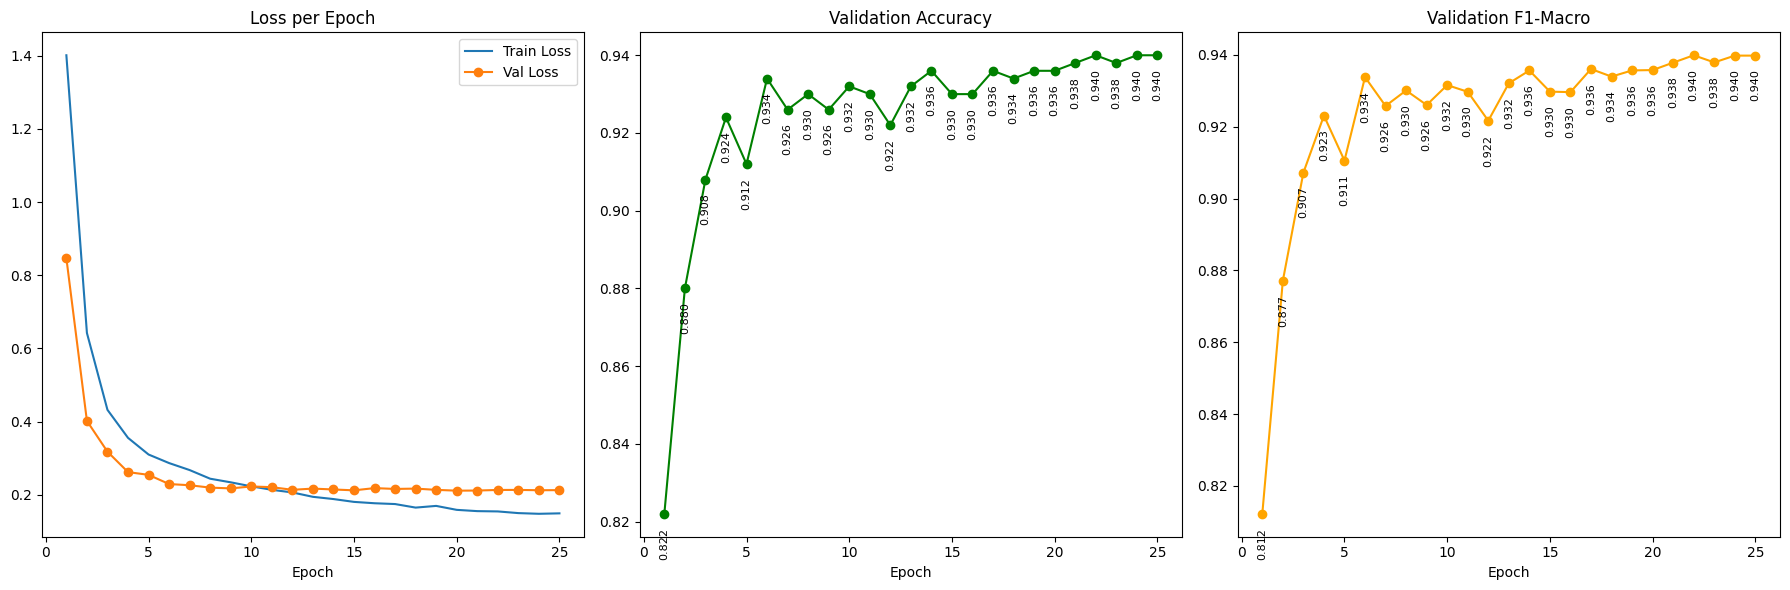

In [ ]:
# Plot training & validation loss
log_history = trainer.state.log_history

processed_val_metrics = {}
for x in log_history:
    if 'eval_loss' in x and 'eval_f1_macro' in x:
        epoch = x['epoch']
        current_f1 = x['eval_f1_macro']
        current_eval_data = (x['eval_loss'], x['eval_accuracy'], x['eval_f1_macro'])

        if epoch not in processed_val_metrics or current_f1 > processed_val_metrics[epoch][2]: # index 2 is eval_f1_macro
            processed_val_metrics[epoch] = current_eval_data

val_metrics_unique_epochs = sorted([(epoch, *metrics) for epoch, metrics in processed_val_metrics.items()])

epochs_val   = [x[0] for x in val_metrics_unique_epochs]
val_loss     = [x[1] for x in val_metrics_unique_epochs]
val_accuracy = [x[2] for x in val_metrics_unique_epochs]
val_f1       = [x[3] for x in val_metrics_unique_epochs]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

train_loss_unique_epochs = {x['epoch']: x['loss'] for x in log_history if 'loss' in x and 'eval_loss' not in x}
train_epochs_sorted = sorted(train_loss_unique_epochs.keys())
train_losses_sorted = [train_loss_unique_epochs[e] for e in train_epochs_sorted]

# Plot Loss per Epoch
axes[0].plot(train_epochs_sorted, train_losses_sorted, label='Train Loss')
axes[0].plot(epochs_val, val_loss, label='Val Loss', marker='o')
axes[0].set_title('Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].legend()

# Plot Accuracy per Epoch
axes[1].plot(epochs_val, val_accuracy, color='green', marker='o')
axes[1].set_title('Validation Accuracy')
axes[1].set_xlabel('Epoch')
for i, txt in enumerate(val_accuracy):
    axes[1].annotate(f'{txt:.3f}', (epochs_val[i], val_accuracy[i]), textcoords="offset points", xytext=(0,-10), ha='center', va='top', fontsize=8, rotation=90)

# Plot F1-macro per Epoch
axes[2].plot(epochs_val, val_f1, color='orange', marker='o')
axes[2].set_title('Validation F1-Macro')
axes[2].set_xlabel('Epoch')
for i, txt in enumerate(val_f1):
    axes[2].annotate(f'{txt:.3f}', (epochs_val[i], val_f1[i]), textcoords="offset points", xytext=(0,-10), ha='center', va='top', fontsize=8, rotation=90)

plt.tight_layout()
plt.savefig('training_curve_wilayah.png', dpi=150)
plt.show()

## 9. Evaluasi pada Test Set

In [ ]:
# Evaluasi keseluruhan
test_results = trainer.evaluate(test_ds)
print('Test Set Results:')
for k, v in test_results.items():
    print(f'  {k}: {v:.4f}' if isinstance(v, float) else f'  {k}: {v}')

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.149218,0.219661,25,0.942000,0.941746


Test Set Results:
  eval_loss: 0.2197
  eval_accuracy: 0.9420
  eval_f1_macro: 0.9417


In [ ]:
predictions = trainer.predict(test_ds)
preds = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids

# Classification report
target_names = [id2label[i] for i in range(len(id2label))]
print('Classification Report:')
print(classification_report(true_labels, preds, target_names=target_names))

Classification Report:
              precision    recall  f1-score   support

          EI       0.94      0.94      0.94       100
         INF       0.95      0.96      0.96       100
         PAR       0.97      1.00      0.99       100
          PE       0.91      0.89      0.90       100
        LAIN       0.94      0.92      0.93       100

    accuracy                           0.94       500
   macro avg       0.94      0.94      0.94       500
weighted avg       0.94      0.94      0.94       500



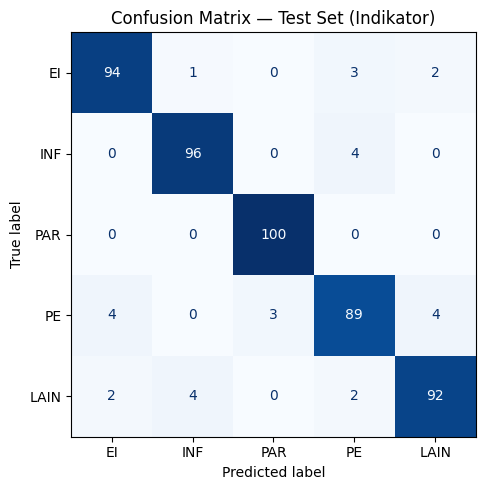

In [ ]:
# Confusion Matrix
cm = confusion_matrix(true_labels, preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Confusion Matrix — Test Set (Indikator)')
plt.tight_layout()
plt.savefig('confusion_matrix_indikator.png', dpi=150)
plt.show()

In [ ]:
import numpy as np

predictions = trainer.predict(test_ds)

logits = predictions.predictions[0] if isinstance(predictions.predictions, tuple) else predictions.predictions
pred_labels = np.argmax(logits, axis=-1)
true_labels = predictions.label_ids

# map label
id2label = {v: k for k, v in label2id.items()}

unique_classes = np.unique(true_labels)

print("\n=== TEBAKAN MODEL ===")

for c in unique_classes:
    indices = np.where(true_labels == c)[0]
    true_label_name = id2label.get(c, f"Kelas {c}")

    print(f"\nKATEGORI ASLI: {true_label_name.upper()}")
    print("="*70)

    for i, idx in enumerate(indices[:3]):
        # input_ids
        raw_input_ids = test_ds[int(idx)]['input_ids']

        if hasattr(raw_input_ids, "tolist"):
            token_list = raw_input_ids.tolist()
        else:
            token_list = raw_input_ids

        if isinstance(token_list, list) and len(token_list) > 0 and isinstance(token_list[0], list):
            token_list = token_list[0]

        # bandingkan teks
        text_clean = tokenizer.decode(token_list, skip_special_tokens=True)
        text_raw = tokenizer.decode(token_list, skip_special_tokens=False)

        pred_label_name = id2label.get(pred_labels[idx], f"Kelas {pred_labels[idx]}")
        status = "✅ BENAR" if c == pred_labels[idx] else "❌ SALAH"

        print(f"[{i+1}] Tebakan Model: {pred_label_name} {status}")
        print(f"Teks (Clean) : '{text_clean[:250]}'")
        print(f"Teks (Raw)   : '{text_raw[:250]}'")
        print("-" * 70)


=== TEBAKAN MODEL ===

KATEGORI ASLI: EI
[1] Tebakan Model: EI ✅ BENAR
Teks (Clean) : 'brief. id hilirisasi sektor pertanian sebagai strategi untuk mendorong pertumbuhan ekspor, meningkatkan kesejahteraan petani, memperkuat ekonomi lokal dan membuka lapangan kerja baru. selama ini indonesia cenderung mengekspor komoditas mentah yang ke'
Teks (Raw)   : '[CLS] brief. id hilirisasi sektor pertanian sebagai strategi untuk mendorong pertumbuhan ekspor, meningkatkan kesejahteraan petani, memperkuat ekonomi lokal dan membuka lapangan kerja baru. selama ini indonesia cenderung mengekspor komoditas mentah y'
----------------------------------------------------------------------
[2] Tebakan Model: LAIN ❌ SALAH
Teks (Clean) : 'jakarta, kompas. com - kinerja perdagangan luar negeri indonesia kembali mencatatkan prestasi. pada kuartal iii - 2025, indonesia berhasil mempertahankan surplus neraca perdagangan, sehingga bisa memperpanjang periode surplus selama 65 bulan secara b'
Teks (Raw)   : '[CLS]

## 10. Simpan Model

In [ ]:
SAVE_DIR        = './indobertbase-lora-indikator-final'
MERGED_SAVE_DIR = './indobertbase-indikator-merged'

# Simpan LoRA adapter weights
model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print(f'LoRA adapter tersimpan di: {SAVE_DIR}')

# Merge LoRA weights ke base model
merged_model = model.merge_and_unload()
merged_model.save_pretrained(MERGED_SAVE_DIR)
tokenizer.save_pretrained(MERGED_SAVE_DIR)
print(f'Merged model tersimpan di: {MERGED_SAVE_DIR}')

# Simpan ke Google Drive
from google.colab import drive
import shutil, os

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

for current_dir_to_save in [SAVE_DIR, MERGED_SAVE_DIR]:
    drive_dest_folder_name = os.path.basename(current_dir_to_save)
    dest = f'/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBERTbase_Indikator/{drive_dest_folder_name}'

    os.makedirs(os.path.dirname(dest), exist_ok=True)

    if os.path.exists(dest):
        shutil.rmtree(dest)

    shutil.copytree(current_dir_to_save, dest)
    print(f'✓ Tersimpan di Google Drive: {dest}')

LoRA adapter tersimpan di: ./indobertbase-lora-indikator-final


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged model tersimpan di: ./indobertbase-indikator-merged
✓ Tersimpan di Google Drive: /content/drive/MyDrive/Skripsi/Fine-tuning/IndoBERTbase_Indikator/indobertbase-lora-indikator-final
✓ Tersimpan di Google Drive: /content/drive/MyDrive/Skripsi/Fine-tuning/IndoBERTbase_Indikator/indobertbase-indikator-merged


## 11. Inference (Uji Coba Prediksi)

In [ ]:
def predict_indikator(text, model, tokenizer, device):
    """Prediksi label indikator satu teks berita."""
    model.eval()
    clean = clean_text(text)
    inputs = tokenizer(
        clean,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors='pt',
        padding=True,
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    logits = outputs.logits
    probs  = torch.softmax(logits, dim=-1).squeeze().cpu().numpy()
    pred   = int(np.argmax(probs))

    return {
        'label': id2label[pred],
        'confidence': float(probs[pred]),
        'probs': {id2label[i]: float(probs[i]) for i in range(len(probs))}
    }

model.to(device)

contoh_inf = "BPS DKI Jakarta mencatat inflasi pada bulan Maret 2025 sebesar 0,15 persen. \
    Kenaikan harga terjadi pada kelompok makanan dan minuman, serta transportasi."

contoh_par = "Dinas Pariwisata DKI Jakarta melaporkan tingkat hunian hotel di Jakarta \
    meningkat 20 persen pada libur akhir tahun 2024 dibandingkan tahun sebelumnya."

contoh_ei = "BPS Provinsi DKI Jakarta mencatat nilai ekspor Jakarta pada Februari 2025 \
    mencapai 1,2 miliar dolar AS, naik 8 persen dibandingkan bulan sebelumnya."

contoh_pe = "BPS merilis angka pertumbuhan ekonomi kuartal IV tahun 2025. \
    Hasilnya, pertumbuhan ekonomi menembus 5% seperti yang diprediksi."

contoh_lain = "Tingkat pengangguran terbuka di DKI Jakarta pada Agustus 2024 tercatat \
    sebesar 6,03 persen, turun dibandingkan periode yang sama tahun lalu."

contoh_list = [
    ('INF', contoh_inf),
    ('PAR', contoh_par),
    ('EI',  contoh_ei),
    ('PE',  contoh_pe),
    ('LAIN',  contoh_lain),
]

print('=== Contoh Prediksi ===')
for expected, teks in contoh_list:
    hasil = predict_indikator(teks, model, tokenizer, device)
    status = '✓' if hasil['label'] == expected else '✗'
    print(f'\n[{status}] Seharusnya {expected} → Prediksi: {hasil["label"]} (confidence: {hasil["confidence"]:.4f})')
    print(f'    Probabilitas: {hasil["probs"]}')

=== Contoh Prediksi ===

[✓] Seharusnya INF → Prediksi: INF (confidence: 0.9963)
    Probabilitas: {'EI': 0.001727591035887599, 'INF': 0.9962794184684753, 'PAR': 1.1391605767130386e-05, 'PE': 0.0017861333908513188, 'LAIN': 0.0001955175684997812}

[✓] Seharusnya PAR → Prediksi: PAR (confidence: 0.9918)
    Probabilitas: {'EI': 0.0004587643488775939, 'INF': 1.7023441614583135e-05, 'PAR': 0.9917710423469543, 'PE': 0.0034543739166110754, 'LAIN': 0.00429877545684576}

[✓] Seharusnya EI → Prediksi: EI (confidence: 0.9786)
    Probabilitas: {'EI': 0.9786106944084167, 'INF': 0.0018508151406422257, 'PAR': 0.008784591220319271, 'PE': 0.006425375118851662, 'LAIN': 0.0043285624124109745}

[✓] Seharusnya PE → Prediksi: PE (confidence: 0.9501)
    Probabilitas: {'EI': 0.005099059548228979, 'INF': 0.02809521183371544, 'PAR': 0.009098939597606659, 'PE': 0.950126588344574, 'LAIN': 0.007580207195132971}

[✗] Seharusnya LAIN → Prediksi: PE (confidence: 0.5976)
    Probabilitas: {'EI': 0.02781195379793644

## 12. Load Model yang Tersimpan

In [ ]:
# Load merge model
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
DRIVE_DIR  = '/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBERTbase-NLU_Indikator/indobertbase-nlu-indikator-merged'
MAX_LENGTH = 512

from transformers import AutoModelForSequenceClassification, AutoTokenizer
tokenizer_loaded = AutoTokenizer.from_pretrained(DRIVE_DIR, local_files_only=True)
model_loaded = AutoModelForSequenceClassification.from_pretrained(
    DRIVE_DIR, local_files_only=True
)
model_loaded.to(device)
model_loaded.eval()
print(f'Model berhasil dimuat dan dipindah ke: {device}')

# Load LoRA adapter
# from peft import PeftModel
# from transformers import AutoModelForSequenceClassification, AutoTokenizer
#
# tokenizer_loaded = AutoTokenizer.from_pretrained('./indobert-lora-indikator-final')
# base = AutoModelForSequenceClassification.from_pretrained(
#     'indolem/indobert-base-uncased', num_labels=4,
#     id2label=id2label, label2id=label2id
# )
# model_loaded = PeftModel.from_pretrained(base, './indobert-lora-indikator-final')
# model_loaded.eval()

Mounted at /content/drive


Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

Model berhasil dimuat dan dipindah ke: cuda


In [ ]:
def clean_text(text):
    if not isinstance(text, str):
        return ''
    # Hapus HTML entities
    text = re.sub(r'&#[0-9]+;', ' ', text)
    text = re.sub(r'&[a-zA-Z]+;', ' ', text)
    # Hapus tag HTML
    text = re.sub(r'<[^>]+>', ' ', text)
    # Hapus URL
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    # Hapus karakter selain huruf, angka, spasi, tanda baca
    text = re.sub(r'[^\w\s.,!?;:\-\'"()]', ' ', text)
    # Normalisasi whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    # Lowercase
    text = text.lower()
    return text

# Label encoding
label2id = {'EI': 0, 'INF': 1, 'PAR': 2, 'PE': 3, 'LAIN' : 4}
id2label = {v: k for k, v in label2id.items()}

def predict_indikator(text, model, tokenizer, device):
    """Prediksi label indikator satu teks berita."""
    model.eval()
    clean = clean_text(text)
    inputs = tokenizer(
        clean,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors='pt',
        padding=True,
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    logits = outputs.logits
    probs  = torch.softmax(logits, dim=-1).squeeze().cpu().numpy()
    pred   = int(np.argmax(probs))

    return {
        'label': id2label[pred],
        'confidence': float(probs[pred]),
        'probs': {id2label[i]: float(probs[i]) for i in range(len(probs))}
    }

In [ ]:
berita = """Gubernur DKI Jakarta, Pramono Anung, menyatakan bahwa partisipasi masyarakat dalam Pendataan Lapangan Sensus Ekonomi 2026 (SE2026) yang dilakukan Badan Pusat Statistik (BPS) penting untuk menghasilkan data ekonomi Jakarta yang akurat, sebagai dasar pemerintah dalam menyusun kebijakan.
Gubernur sendiri menerima menerima petugas BPS DKI Jakarta yang melakukan pendataan Sensus Ekonomi 2026, baru-baru ini.
"Petugas BPS yang datang hari ini secara langsung menanyakan sesuai dengan tugas dalam melakukan sensus. Saya menjawab secara apa adanya, sesuai kondisi sebenarnya," kata Pramono.
Ia kemudian mendorong masyarakat yang belum terdata maupun yang masih ragu memberikan informasi agar terbuka kepada petugas BPS. Menurutnya, data yang akurat membantu pemerintah memahami kondisi perekonomian Jakarta secara lebih utuh.
"Saya mengimbau kepada masyarakat di Jakarta untuk membantu BPS dalam melakukan tugas mereka, yaitu sensus ekonomi. Saya mengimbau seluruh masyarakat Jakarta untuk memberikan data apa adanya. Jangan tertutup," ujarnya.
Pramono menegaskan, informasi yang diberikan dalam Sensus Ekonomi 2026 bersifat rahasia. Pendataan dipastikan tidak berkaitan dengan perpajakan ataupun kepentingan lain di luar kebutuhan statistik.
"Ini betul-betul adalah sensus ekonomi untuk mengetahui potret kondisi dan keadaan di Jakarta. Masyarakat diminta memberikan jawaban apa adanya, sesuai dengan kondisi yang sebenarnya, karena data ini akan menjadi referensi dalam mengambil keputusan," tutur Pramono.
Sebagai salah satu pusat kegiatan ekonomi terbesar di Indonesia, keberagaman kegiatan usaha yang tumbuh di Jakarta, mulai dari usaha rumahan, UMKM, hingga perusahaan berskala besar dan internasional, perlu tercatat agar gambaran perekonomian Jakarta tidak hanya mencerminkan kegiatan usaha yang terlihat secara kasatmata.
Selama pendataan, petugas BPS mendatangi berbagai lokasi usaha, seperti mal, kawasan bisnis, pasar, pertokoan, pusat perbelanjaan, rumah, dan apartemen untuk bertemu langsung dengan pelaku usaha dan masyarakat.
Sementara, sebagian responden mengikuti pendataan melalui pengisian kuesioner secara mandiri.
Sensus Ekonomi ini bukan hanya menghitung jumlah usaha. Data yang dikumpulkan mencakup jenis kegiatan usaha, produk dan jasa yang dihasilkan, skala usaha, tenaga kerja, pemanfaatan teknologi, serta berbagai karakteristik lainnya.
Data itu diharapkan memberikan gambaran yang lebih lengkap mengenai perkembangan ekonomi Jakarta, termasuk usaha yang selama ini belum tercatat dalam data administrasi pemerintah.
Untuk diketahui, hasil SE2026 akan menjadi salah satu rujukan Pemerintah Provinsi (Pemprov) DKI Jakarta dalam menyusun program, kebijakan, regulasi, dan intervensi yang lebih tepat sasaran berdasarkan kondisi ekonomi terkini.
"Data yang benar akan membantu pemerintah mengambil keputusan yang benar. Karena itu saya mengajak masyarakat untuk ikut menyukseskan sensus ekonomi," ujar Gubernur.
Dalam kesempatan yang sama, ia juga meminta Dinas Pendidikan DKI Jakarta melakukan pengecekan ulang terhadap mahasiswa penerima Kartu Jakarta Mahasiswa Unggul (KJMU) yang terdampak perubahan data desil.
Langkah ini bertujuan memastikan mahasiswa yang sebelumnya menerima KJMU tidak kehilangan akses pendidikan akibat perubahan data yang masih perlu diverifikasi.
Sementara itu, Sekretaris Utama BPS RI, Zulkipli, mengatakan pelaksanaan pendataan Sensus Ekonomi 2026 di Jakarta berjalan lancar.
Berdasarkan pre-list yang tersedia, BPS telah melakukan pendataan sebesar 111 persen. Hingga kini, masih terdapat sejumlah unit usaha yang belum ditemukan atau dokumennya masih dalam proses penelusuran.
"Waktu kita masih ada sampai dengan 15 September. Kami akan mendatangi kembali perusahaan-perusahaan itu serta menemukan kembali yang tadinya belum ditemukan dalam pre-list kami," kata Zulikpli.
Zulkipli juga mengajak masyarakat dan pelaku usaha yang belum terdata untuk menghubungi Kantor BPS. Pendataan masih akan berlangsung hingga pertengahan September 2026.
"Untuk masyarakat di DKI Jakarta dapat membantu BPS dalam pelaksanaan Sensus Ekonomi 2026. Bagi yang belum terdata, nanti kita bisa lakukan pendataan atau bisa menghubungi kantor BPS. Waktu kita masih ada hingga pertengahan September 2026," pungkas Zulkipli.
https://www.cnnindonesia.com/nasional/20260901114547-25-1398660/gubernur-dki-ikuti-sensus-ekonomi-dorong-warga-terbuka-pada-petugas"""


import time

def predict_indikator(text, model, tokenizer, device):
    """Prediksi label indikator satu teks berita."""
    model.eval()
    clean = clean_text(text)
    inputs = tokenizer(
        clean,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors='pt',
        padding=True,
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    logits = outputs.logits
    probs  = torch.softmax(logits, dim=-1).squeeze().cpu().numpy()
    pred   = int(np.argmax(probs))

    return {
        'label': id2label[pred],
        'confidence': float(probs[pred]),
        'probs': {id2label[i]: float(probs[i]) for i in range(len(probs))}
    }

def timed_predict(text, model, tokenizer, device):
    """Prediksi + ukur runtime inferensi (dalam detik) untuk satu teks (single run)."""
    if device.type == 'cuda':
        torch.cuda.synchronize()  # cek GPU tidak beroperasi

    start = time.perf_counter()
    hasil = predict_indikator(text, model, tokenizer, device)
    if device.type == 'cuda':
        torch.cuda.synchronize()  # tunggu GPU selesai sebelum stop timer
    end = time.perf_counter()
    duration_s = (end - start)

    return hasil, duration_s

# print hasil klasifikasi loaded model
hasil, durasi_s = timed_predict(berita, model_loaded, tokenizer_loaded, device)

print('=== Hasil Klasifikasi (Model Tersimpan) ===')
print(f"Prediksi   : {hasil['label']}")
print(f"Confidence : {hasil['confidence']:.4f}")
print(f"Probabilitas: {hasil['probs']}")

# print inference time
print(f"\n=== Runtime Inferensi ({device}) — satu kali percobaan ===")
print(f"Waktu Eksekusi : {durasi_s:.3f} s")

=== Hasil Klasifikasi (Model Tersimpan) ===
Prediksi   : LAIN
Confidence : 0.7257
Probabilitas: {'EI': 0.1418970674276352, 'INF': 0.0655716210603714, 'PAR': 0.005155584774911404, 'PE': 0.06166972219944, 'LAIN': 0.7257059812545776}

=== Runtime Inferensi (cuda) — satu kali percobaan ===
Waktu Eksekusi : 1.699 s


In [ ]:
# inference_time pada test set
import numpy as np

test_texts  = df_test['text'].tolist()
test_labels = df_test['label'].tolist()

# Warm-up
for text in test_texts:
    _ = predict_indikator(text, model_loaded, tokenizer_loaded, device)

durasi_test_s = []
pred_test     = []

for text in test_texts:
    if device.type == 'cuda':
        torch.cuda.synchronize()   # cek GPU tidak beroperasi
    start = time.perf_counter()
    hasil = predict_indikator(text, model_loaded, tokenizer_loaded, device)
    if device.type == 'cuda':
        torch.cuda.synchronize()   # tunggu GPU selesai sebelum stop timer
    end = time.perf_counter()

    durasi_test_s.append(end - start)
    pred_test.append(hasil['label'])

durasi_test_s = np.array(durasi_test_s)

print(f"=== Runtime Inferensi pada Test Set ({len(test_texts)} data, {device}) ===")
print(f"Rata-rata             : {durasi_test_s.mean():.3f} s")
print(f"Std. dev              : {durasi_test_s.std():.3f} s")
print(f"Median                : {np.median(durasi_test_s):.3f} s")
print(f"Min / Max             : {durasi_test_s.min():.3f} s / {durasi_test_s.max():.3f} s")
print(f"Total waktu           : {durasi_test_s.sum():.2f} s")
print(f"Throughput            : {len(test_texts)/durasi_test_s.sum():.2f} sampel/detik")

=== Runtime Inferensi pada Test Set (500 data, cuda) ===
Rata-rata             : 0.029 s
Std. dev              : 0.014 s
Median                : 0.024 s
Min / Max             : 0.014 s / 0.089 s
Total waktu           : 14.65 s
Throughput            : 34.14 sampel/detik
